# 01 · Images are numbers, and adding noise

Before any AI gets involved, two ideas:

1. **An image is just a grid of numbers.**
2. **The "forward process"**: we can bury any image under noise, one small step at a time, until it is pure static.

Our example image is **Blip**, the alien from my portfolio.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # lets us import the small `diffusion` helper package
OUT = pathlib.Path("../outputs"); OUT.mkdir(exist_ok=True)

import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "#0a0d1f", "axes.facecolor": "#0a0d1f", "text.color": "#e9ecf8",
                     "axes.labelcolor": "#e9ecf8", "xtick.color": "#8f97ba", "ytick.color": "#8f97ba",
                     "axes.edgecolor": "#2a2f55", "font.size": 11})
torch.manual_seed(0)

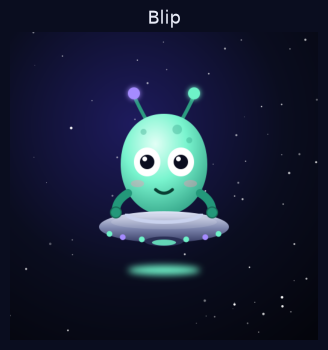

In [2]:
from PIL import Image
blip = Image.open("../assets/blip.png").convert("RGB")
plt.figure(figsize=(4, 4)); plt.imshow(blip); plt.axis("off"); plt.title("Blip"); plt.show()

## 1. An image is a grid of numbers

Every pixel is a number for **brightness**, from 0 (black) to 255 (white).
A colour image is **three grids stacked**: one for red, one for green, one for blue.

Let's zoom into a tiny 8 × 8 patch, where Blip's arm meets the saucer, and print the actual numbers.

shape: (512, 512, 3) | smallest: 4 | largest: 255


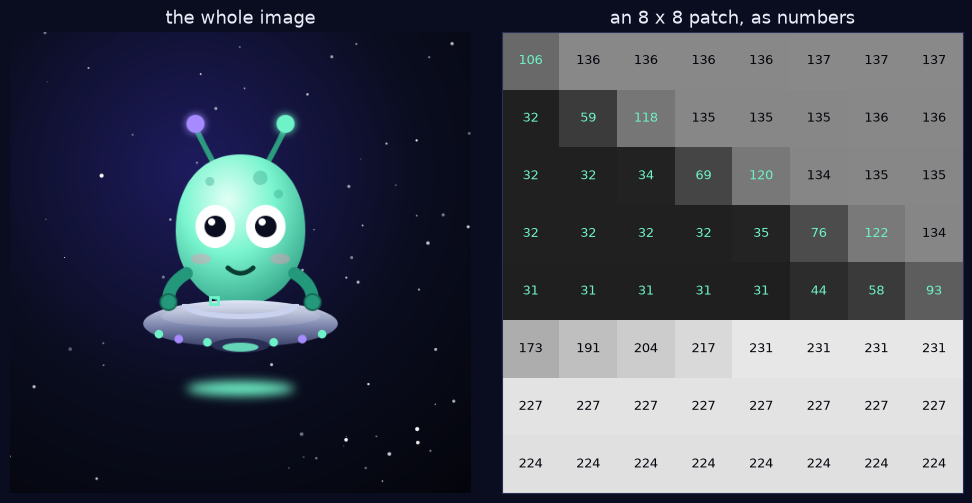

In [3]:
pixels = np.array(blip)            # shape: (height, width, 3 colour channels)
print("shape:", pixels.shape, "| smallest:", pixels.min(), "| largest:", pixels.max())

y, x = 294, 222                    # top-left corner of the patch (where Blip's arm meets the saucer)
patch = pixels[y:y + 8, x:x + 8]
gray = patch.mean(axis=2).astype(int)   # average the 3 channels to get one brightness number

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 5))
a.imshow(blip); a.add_patch(plt.Rectangle((x, y), 8, 8, fill=False, ec="#6ef2c8", lw=2)); a.axis("off"); a.set_title("the whole image")
b.imshow(gray, cmap="gray", vmin=0, vmax=255)
for i in range(8):
    for j in range(8):
        b.text(j, i, gray[i, j], ha="center", va="center", fontsize=9, color="#6ef2c8" if gray[i, j] < 128 else "#04050c")
b.set_xticks([]); b.set_yticks([]); b.set_title("an 8 x 8 patch, as numbers")
plt.tight_layout(); plt.savefig(OUT / "01_pixels.png", dpi=120); plt.show()

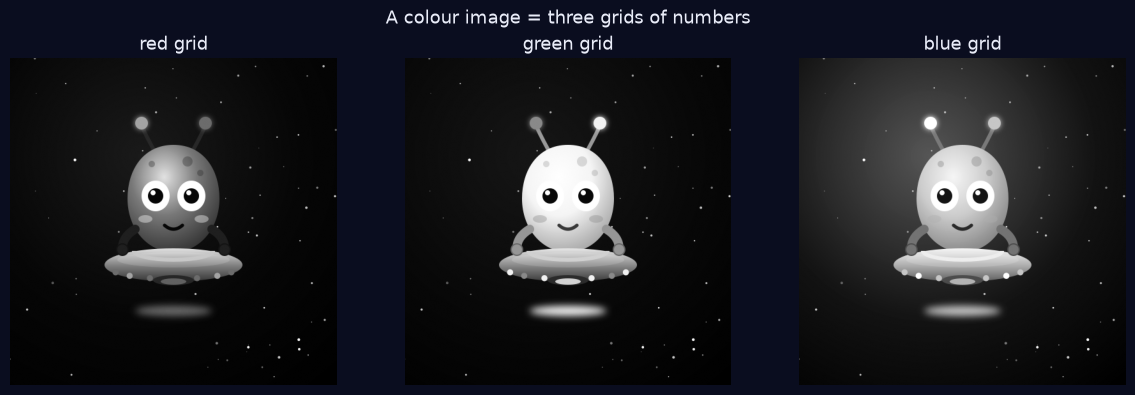

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, c, name, cmap in zip(axes, range(3), ["red", "green", "blue"], ["Reds_r", "Greens_r", "Blues_r"]):
    ax.imshow(pixels[:, :, c], cmap="gray"); ax.axis("off"); ax.set_title(f"{name} grid")
plt.suptitle("A colour image = three grids of numbers", color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "01_rgb_channels.png", dpi=120); plt.show()

## 2. Adding noise, a little at a time

The **forward process** is a fixed recipe. No AI, no learning:

- take the image,
- shrink it very slightly and add a tiny bit of random static,
- repeat **1,000 times**.

After enough steps nothing of Blip is left, just static. Because we pick the amount of noise ourselves,
we always know exactly how much went in at each step. That matters later: it becomes the answer key.

Written out, one step is: `next = sqrt(1 - beta) * current + sqrt(beta) * random_noise`, where `beta` is a small number (0.0001 at the start, growing to 0.02).

In [5]:
steps = 1000
betas = torch.linspace(1e-4, 0.02, steps)      # how much fresh noise each step adds

# work on a 128 x 128 Blip, with pixel values rescaled from 0..255 to -1..1 (what the model will use)
img = torch.tensor(np.array(blip.resize((128, 128))), dtype=torch.float32).permute(2, 0, 1) / 127.5 - 1

x = img.clone()
frames = {0: x.clone()}
for t in range(steps):
    noise = torch.randn_like(x)
    x = (1 - betas[t]).sqrt() * x + betas[t].sqrt() * noise   # one small step
    frames[t + 1] = x.clone()

to_image = lambda v: ((v.clamp(-1, 1) + 1) * 127.5).byte().permute(1, 2, 0).numpy()

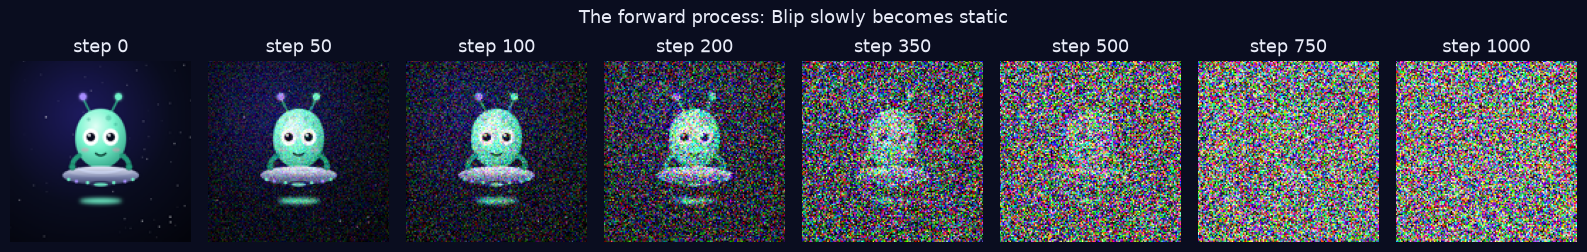

In [6]:
show = [0, 50, 100, 200, 350, 500, 750, 1000]
fig, axes = plt.subplots(1, len(show), figsize=(16, 2.6))
for ax, t in zip(axes, show):
    ax.imshow(to_image(frames[t])); ax.axis("off"); ax.set_title(f"step {t}")
plt.suptitle("The forward process: Blip slowly becomes static", color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "02_forward_strip.png", dpi=120); plt.show()

In [7]:
import imageio.v2 as imageio
gif = [to_image(frames[t]) for t in range(0, 1001, 20)]
gif = [gif[0]] * 10 + gif + [gif[-1]] * 10    # pause on Blip at the start and on static at the end
imageio.mimsave(OUT / "02_forward_noise.gif", gif, duration=0.08, loop=0)
print("saved outputs/02_forward_noise.gif with", len(gif), "frames")

saved outputs/02_forward_noise.gif with 71 frames


### A shortcut: jumping straight to any step

Doing 1,000 small steps every time is slow. Because the recipe is fixed, there's a formula that jumps straight to step `t`:
`x_t = sqrt(alpha_bar_t) * original + sqrt(1 - alpha_bar_t) * noise`.

`alpha_bar_t` is simply **how much of the original image is left after t steps**. Training uses this shortcut, because it needs millions of noisy examples.

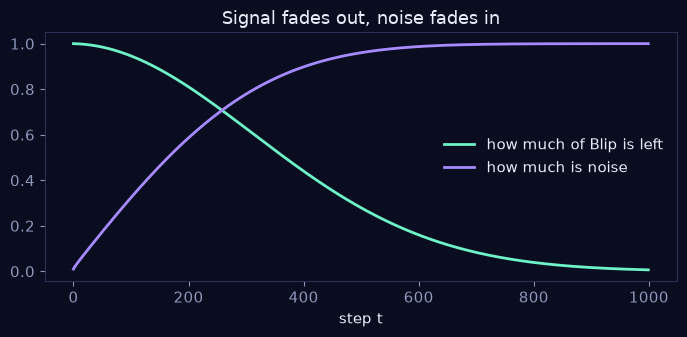

after 1000 steps, 0.64% of the original is left


In [8]:
alpha_bars = torch.cumprod(1 - betas, dim=0)
plt.figure(figsize=(7, 3.5))
plt.plot(alpha_bars.sqrt(), color="#6ef2c8", lw=2, label="how much of Blip is left")
plt.plot((1 - alpha_bars).sqrt(), color="#a58bff", lw=2, label="how much is noise")
plt.xlabel("step t"); plt.legend(frameon=False); plt.title("Signal fades out, noise fades in")
plt.tight_layout(); plt.savefig(OUT / "02_signal_left.png", dpi=120); plt.show()
print(f"after 1000 steps, {alpha_bars[-1].sqrt() * 100:.2f}% of the original is left")

**Takeaway:** the forward process is pure arithmetic. The interesting part is the reverse: getting from static back to an image. That needs a model that has learned to *guess the noise*, which is notebook **02**.